## Step 1: Import necessary libraries

In [77]:

import numpy as np
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt

# Make results the same every time you run the code (very important for homework)
np.random.seed(2)

## Generate linear dataset with small noise

In [213]:
n_samples = 100
X = np.linspace(-2, 2, n_samples).reshape(-1, 1)     
y_true = 3 * X[:, 0] + 1                             
noise = np.random.normal(0, 0.2, n_samples)
X_test = np.linspace(-2, 2, 500).reshape(-1, 1)
y_test_true = 3 * X_test[:, 0] + 1


## what does the data set look?

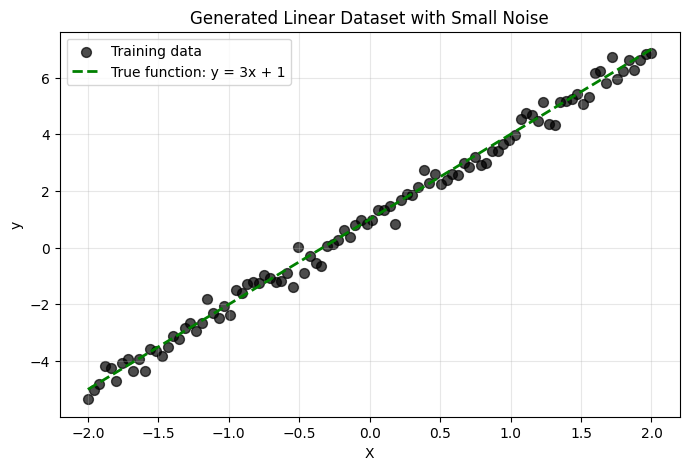

In [216]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='black', s=50, alpha=0.7, label='Training data')
plt.plot(X_test, y_test_true, color='green', linewidth=2, linestyle='--',
         label='True function: y = 3x + 1')
plt.title('Generated Linear Dataset with Small Noise')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Step 2: Initial prediction = mean of all targets 

In [219]:
initial_pred = np.mean(y)                       
current_pred = np.full(n_samples, initial_pred) 
residuals = y - current_pred

In [221]:
residuals

array([-6.28845396, -5.9498977 , -5.74517299, -5.12908564, -5.19742513,
       -5.66321964, -5.01661392, -4.87420283, -5.29186583, -4.88479903,
       -5.28615306, -4.51067332, -4.58331558, -4.77239613, -4.45563468,
       -4.0529859 , -4.16964397, -3.79268897, -3.59553579, -3.89225568,
       -3.61259185, -2.7542951 , -3.24015473, -3.40932291, -3.01592343,
       -3.31442671, -2.4518141 , -2.55933435, -2.22347176, -2.15734774,
       -2.1897005 , -1.89292449, -2.0068931 , -2.14181578, -2.12899545,
       -1.83518128, -2.33115415, -0.91050625, -1.85131269, -1.23887222,
       -1.48993841, -1.58113418, -0.8769176 , -0.82243184, -0.65773698,
       -0.32392365, -0.55290815, -0.13254504,  0.02900418, -0.10421237,
        0.03239713,  0.40019238,  0.37705251,  0.52881589, -0.11001934,
        0.74106957,  0.95768949,  0.9252939 ,  1.18792247,  1.77967485,
        1.35518353,  1.6503866 ,  1.31699979,  1.43750802,  1.67042715,
        1.62974007,  2.05456658,  1.89790985,  2.24677211,  1.98

## Step 3: Train the first weak tree on the residuals

In [224]:
tree1 = DecisionTreeRegressor(max_depth=2, random_state=2)
tree1.fit(X, residuals)  
current_pred = current_pred + tree1.predict(X)

## Step 4: Run 20 iterations 

In [227]:
trees = [tree1]                              
for i in range(1, 20):
    residuals = y - current_pred
    tree = DecisionTreeRegressor(max_depth=2, random_state=2)
    tree.fit(X, residuals)
    trees.append(tree)
    current_pred = current_pred + tree.predict(X)
    if (i+1) in [1, 5, 20]:
        print(f"Iteration {i+1:2d}/20 completed.")

Iteration  5/20 completed.
Iteration 20/20 completed.


## Step 5: Plot initial + after 1, 5, and 20 iterations

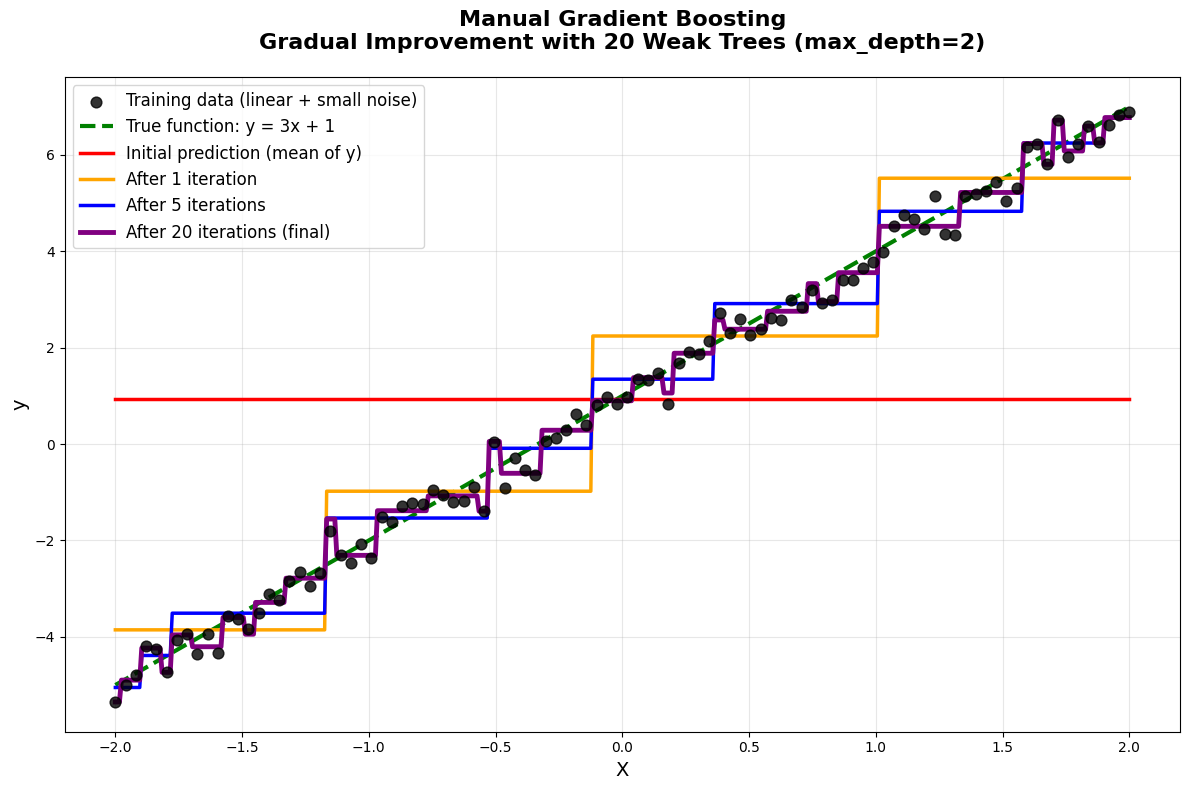

In [230]:
plt.figure(figsize=(12, 8))

plt.scatter(X, y, color='black', s=60, alpha=0.8,
            label='Training data (linear + small noise)', zorder=5)

plt.plot(X_test, y_test_true, color='green', linewidth=3, linestyle='--',
         label='True function: y = 3x + 1')


pred_0 = np.full_like(X_test, initial_pred)
plt.plot(X_test, pred_0, color='red', linewidth=2.5,
         label='Initial prediction (mean of y)')


pred_1 = initial_pred + trees[0].predict(X_test)
plt.plot(X_test, pred_1, color='orange', linewidth=2.5,
         label='After 1 iteration')

pred_5 = initial_pred
for tree in trees[:5]:
    pred_5 += tree.predict(X_test)
plt.plot(X_test, pred_5, color='blue', linewidth=2.5,
         label='After 5 iterations')

pred_20 = initial_pred
for tree in trees:
    pred_20 += tree.predict(X_test)
plt.plot(X_test, pred_20, color='purple', linewidth=3.5,
         label='After 20 iterations (final)')

plt.title('Manual Gradient Boosting\nGradual Improvement with 20 Weak Trees (max_depth=2)',
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('X', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## mse and R-Squared 

In [211]:

from sklearn.metrics import r2_score, mean_squared_error

def predict_at_stage(stage):
    pred = np.full_like(X_test[:, 0], initial_pred)
    for tree in trees[:stage]:
        pred += tree.predict(X_test)
    return pred

stages = [1, 5, 20]
results = []

for stage in stages:
    y_pred_stage = predict_at_stage(stage)
    r2 = r2_score(y_test_true, y_pred_stage)
    mse = mean_squared_error(y_test_true, y_pred_stage)
    results.append((stage, r2, mse))

print("نتایج ارزیابی مدل در مراحل مختلف (با σ = ۰.۲ و ۱۰۰ نمونه)")
print("-------------------------------------------------------------")
print(f"{'مرحله':<10} {'R²':<15} {'MSE':<15}")
print("-------------------------------------------------------------")
for stage, r2, mse in results:
    print(f"{stage:<10} {r2:>10.4f}    {mse:>10.6f}")
print("-------------------------------------------------------------")

print(f"مدل نهایی (۲۰ تکرار):   R² = {results[-1][1]:.4f}    MSE = {results[-1][2]:.6f}")

نتایج ارزیابی مدل در مراحل مختلف (با σ = ۰.۲ و ۱۰۰ نمونه)
-------------------------------------------------------------
مرحله      R²              MSE            
-------------------------------------------------------------
1              0.9350      0.783706
5              0.9813      0.225708
20             0.9929      0.085190
-------------------------------------------------------------
مدل نهایی (۲۰ تکرار):   R² = 0.9929    MSE = 0.085190
